In [1]:
from inspect import Signature

from pydicom.datadict import mask1

import osipy
import numpy as np
import matplotlib.pyplot as plt
from osipy.ivim import FittingMethod, IVIMFitParams

In [2]:
import hashlib
import tempfile
import urllib.request
import zipfile
from pathlib import Path

ZENODO_URL = "https://zenodo.org/api/records/14605039/files/OSIPI_TF24_data_phantoms.zip/content"
ZENODO_MD5 = "e7b3fe1d811a7a45c5aaf6c604c82793"

tmp_dir = Path(tempfile.mkdtemp(prefix="osipi_tf24_"))
zip_path = tmp_dir / "OSIPI_TF24_data_phantoms.zip"
data_dir = tmp_dir / "data"

# Download
urllib.request.urlretrieve(ZENODO_URL, zip_path)

# Verify checksum
md5 = hashlib.md5()
with open(zip_path, "rb") as f:
    for chunk in iter(lambda: f.read(1 << 20), b""):
        md5.update(chunk)
assert md5.hexdigest() == ZENODO_MD5, "Checksum mismatch"

# Unpack
with zipfile.ZipFile(zip_path) as zf:
    zf.extractall(data_dir)

print(f"Data extracted to: {data_dir}")
for p in sorted(data_dir.rglob("*")):
    print(p.relative_to(data_dir))

Data extracted to: /tmp/osipi_tf24_14m1rqco/data
Data
Data/abdomen.bval
Data/abdomen.nii.gz
Data/abdomen_readme.txt
Data/brain.bval
Data/brain.bvec
Data/brain.nii.gz
Data/brain_mask_gray_matter.nii.gz
Data/brain_mask_white_matter.nii.gz
Data/brain_readme.txt
Data/brain_seg_all.nii.gz
Data/mask_abdomen_homogeneous.nii.gz
Data/mask_full_temp.nii.gz
Phantoms
Phantoms/XCAT_MAT_RESP
Phantoms/XCAT_MAT_RESP/XCAT5D_RP_10_CP_1.mat
Phantoms/XCAT_MAT_RESP/XCAT5D_RP_11_CP_1.mat
Phantoms/XCAT_MAT_RESP/XCAT5D_RP_12_CP_1.mat
Phantoms/XCAT_MAT_RESP/XCAT5D_RP_13_CP_1.mat
Phantoms/XCAT_MAT_RESP/XCAT5D_RP_14_CP_1.mat
Phantoms/XCAT_MAT_RESP/XCAT5D_RP_15_CP_1.mat
Phantoms/XCAT_MAT_RESP/XCAT5D_RP_16_CP_1.mat
Phantoms/XCAT_MAT_RESP/XCAT5D_RP_17_CP_1.mat
Phantoms/XCAT_MAT_RESP/XCAT5D_RP_18_CP_1.mat
Phantoms/XCAT_MAT_RESP/XCAT5D_RP_19_CP_1.mat
Phantoms/XCAT_MAT_RESP/XCAT5D_RP_1_CP_1.mat
Phantoms/XCAT_MAT_RESP/XCAT5D_RP_20_CP_1.mat
Phantoms/XCAT_MAT_RESP/XCAT5D_RP_2_CP_1.mat
Phantoms/XCAT_MAT_RESP/XCAT5D_RP_3_C

In [3]:
data_path = data_dir/"Data/abdomen.nii.gz"
bval_path = data_dir/"Data/abdomen.bval"
mask_path = data_dir/"Data/mask_abdomen_homogeneous.nii.gz"
dataset = osipy.load_nifti(data_path)
mask = osipy.load_nifti(mask_path)
mask = mask.data.astype(bool)

with open(bval_path, "r") as f:
    bvals = [int(x) for x in f.read().split()]

print(f"Number of b values: {len(bvals)}")
print(f"data shape: {dataset.shape}")
print(f"Mask shape: {mask.shape}")

Number of b values: 104
data shape: (144, 144, 21, 104)
Mask shape: (144, 144, 21)


In [4]:
# Select a sample voxel with good signal
sample_indices = np.where(mask)
center_idx = len(sample_indices[0]) // 2
x, y, z = sample_indices[0][center_idx], sample_indices[1][center_idx], sample_indices[2][center_idx]
# Select a sample voxel with good signal
sample_indices = np.where(mask)
center_idx = len(sample_indices[0]) // 2
x, y, z = sample_indices[0][center_idx], sample_indices[1][center_idx], sample_indices[2][center_idx]


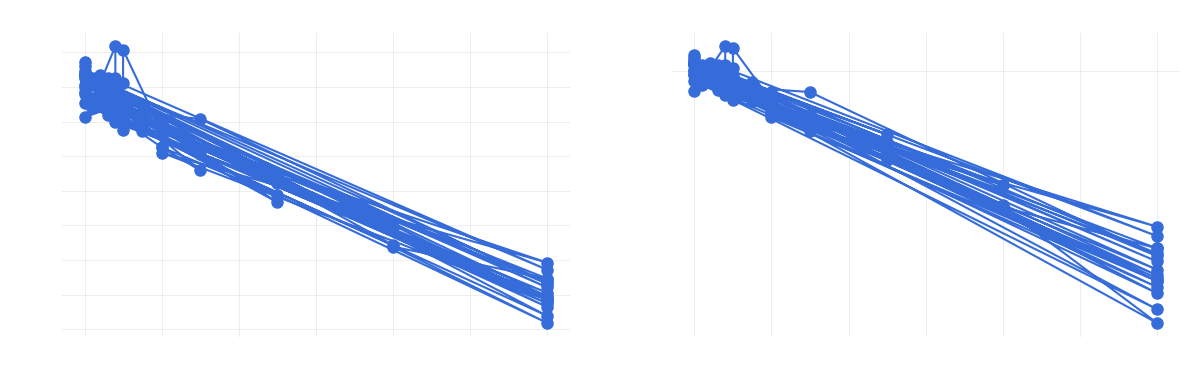

In [5]:
# Extract signal at all b-values
signal = dataset.data[x, y, z, :]

# Normalize to b=0
s0 = signal[0]
signal_norm = signal / s0

# Plot (opaque white background so it is readable in dark themes)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), facecolor='white')
for ax in axes:
    ax.set_facecolor('white')

# Linear scale
axes[0].plot(bvals, signal_norm, 'o-', markersize=8)
axes[0].set_xlabel('b-value (s/mm²)')
axes[0].set_ylabel('S/S₀')
axes[0].set_title('Signal Decay (Linear)')
axes[0].grid(True, alpha=0.3)

# Log scale - should show bi-exponential behavior
axes[1].semilogy(bvals, signal_norm, 'o-', markersize=8)
axes[1].set_xlabel('b-value (s/mm²)')
axes[1].set_ylabel('S/S₀ (log scale)')
axes[1].set_title('Signal Decay (Log) - Look for curvature at low b')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()

In [6]:
params = IVIMFitParams(method=FittingMethod.SEGMENTED_WLS, signal_model="biexponential")

result = osipy.fit_ivim(
    signal=dataset.data,
    b_values=bvals,
    mask=mask,
    params=params
)

ValueError: operands could not be broadcast together with shapes (104,1932) (104,1927) 